# QLoRA lab: fine-tuning Qwen2.5-1.5B to summarize dialogues


## Setup


In [60]:
 %pip install -q -U bitsandbytes rouge_score
 %pip install -y torchao          # only if peft raises "Found an incompatible version of torchao"


Usage:   
  pip3 install [options] <requirement specifier> [package-index-options] ...
  pip3 install [options] -r <requirements file> [package-index-options] ...
  pip3 install [options] [-e] <vcs project url> ...
  pip3 install [options] [-e] <local project path> ...
  pip3 install [options] <archive url/path> ...

no such option: -y


In [61]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import math
import random
import time
from pathlib import Path

import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
N_TRAIN = 2000           # training dialogues (of 12,460); more data trains longer
N_EVAL = 60              # validation dialogues for ROUGE and human evaluation
MAX_LEN = 512            # longest training example in tokens; longer ones are dropped, not truncated
OUT = Path("/kaggle/working/qlora_dialogsum") if Path("/kaggle/working").is_dir() else Path("qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
HAS_GPU = torch.cuda.is_available()

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-2 only)")

torch 2.11.0+cu130 | transformers 5.20.2
GPU: Tesla T4


## Exercise 1 - Will it fit? (2 marks)

Before downloading anything, estimate the memory. Qwen2.5-1.5B has 1,543,714,304 parameters. Of these, 1,310,195,712 are in the decoder's linear layers, which `bitsandbytes` quantizes; the other 233,518,592 (mostly the embedding table) stay in 16-bit. LoRA with `r = 16` on all linear layers adds 18,464,768 trainable parameters. (These counts come from the model's `config.json`, as in the lectures.)



In [62]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 1_543_714_304, 1_310_195_712, 233_518_592, 18_464_768
NF4_BYTES = (4 + 0.127) / 8          # 4-bit codes + double-quantized block scales

In [63]:
def memory_budget(n_total, n_linear, n_other, n_lora):
    """Return {"full FT": GB, "LoRA": GB, "QLoRA": GB}, before activations."""
    full = 16 * n_total
    lora = 2 * n_total + 16 * n_lora
    qlora = NF4_BYTES * n_linear + 4 * n_other + 16 * n_lora
    return {"full FT": full / GB, "LoRA": lora / GB, "QLoRA": qlora / GB}

In [64]:
estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB   fits on a 16 GB T4 before activations: {gb < 16}")
assert abs(estimate["full FT"] - 24.70) < 0.01 and abs(estimate["LoRA"] - 3.38) < 0.01
assert abs(estimate["QLoRA"] - 1.91) < 0.01
print("Exercise 1 checks passed.")

full FT   24.70 GB   fits on a 16 GB T4 before activations: False
LoRA       3.38 GB   fits on a 16 GB T4 before activations: True
QLoRA      1.91 GB   fits on a 16 GB T4 before activations: True
Exercise 1 checks passed.


**Question 1.** (a) Which of the three jobs fit on a T4 before activations? (b) For this 1.5B model, plain LoRA in 16-bit would also fit. Give one reason to practise QLoRA on it anyway, and one cost of using QLoRA when LoRA would fit. (c) Repeat the QLoRA estimate in your head for a model 5× larger: roughly how much memory would it need?

**answer - Question 1:**

(a) Before activations: full fine-tuning needs about 24.70 GB, which does **not** fit on a 16 GB T4. LoRA needs about 3.38 GB and QLoRA about 1.91 GB; both fit.

(b) *Reason to practise QLoRA anyway:* the technique scales. The same recipe lets you fine-tune 7B-70B models on a single GPU, and a 1.5B model is a cheap place to learn it and debug the pipeline. *Cost:* quantization adds rounding error to the frozen weights, and 4-bit dequantization on the fly plus gradient checkpointing make each step slower than 16-bit LoRA, so we pay in speed and some fidelity for memory we do not need.

(c) Roughly 5 × 1.91 ≈ **9.5 GB** (the weight, non-quantized and adapter terms all scale about linearly with size), still before activations, so it would fit on a 16 GB T4 only with small batches and short sequences.

## The data



In [65]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
print(raw)
tokenizer = AutoTokenizer.from_pretrained(CKPT)
print("pad token:", tokenizer.pad_token, tokenizer.pad_token_id)

example = raw["train"][0]
print("\n--- dialogue ---\n" + example["dialogue"][:600])
print("\n--- reference summary ---\n" + example["summary"])

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})
pad token: <|endoftext|> 151643

--- dialogue ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1



### The prompt



In [66]:
INSTRUCTION = ("Summarize the following dialogue in one or two sentences. "
               "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.")
END = "<|im_end|>"                     # Qwen's end-of-turn token: the model must learn to emit it to stop


def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)


print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



## Exercise 2 - Training examples with a masked prompt (4 marks)

In [67]:
def build_example(dialogue, summary):
    prompt_ids = tokenizer(make_prompt(dialogue), add_special_tokens=False)["input_ids"]
    answer_ids = tokenizer(summary + END, add_special_tokens=False)["input_ids"]
    input_ids = prompt_ids + answer_ids
    return {
        "input_ids": input_ids,
        "attention_mask": [1] * len(input_ids),
        "labels": [-100] * len(prompt_ids) + answer_ids,
    }

In [68]:
ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert set(ex) >= {"input_ids", "attention_mask", "labels"}
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "answer labels must equal the answer tokens"
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END), "the answer must end with <|im_end|>"
answer = tokenizer.decode([t for t in ex["labels"] if t != -100])
print(f"{len(ex['input_ids'])} tokens, of which {len(ex['input_ids']) - n_prompt} are scored")
print("scored text:", answer)
print("Exercise 2 checks passed.")

347 tokens, of which 39 are scored
scored text: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


Now we build the training and evaluation sets. Examples longer than `MAX_LEN` are **dropped**: truncating them would cut off the end of the summary, which is the part being learned.

In [69]:
train_rows = raw["train"].shuffle(seed=SEED).select(range(N_TRAIN))
train_data = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_data]
train_data = [e for e in train_data if len(e["input_ids"]) <= MAX_LEN]
print(f"training examples: {len(train_data)} kept, {N_TRAIN - len(train_data)} dropped (> {MAX_LEN} tokens)")
print(f"tokens per example: median {sorted(lengths)[len(lengths) // 2]}, max {max(lengths)}")
print(f"scored (summary) tokens: {sum(sum(l != -100 for l in e['labels']) for e in train_data):,} "
      f"of {sum(len(e['input_ids']) for e in train_data):,} in total")

eval_rows = raw["validation"].shuffle(seed=SEED).select(range(N_EVAL))
eval_dialogues, eval_refs = list(eval_rows["dialogue"]), list(eval_rows["summary"])

training examples: 1940 kept, 60 dropped (> 512 tokens)
tokens per example: median 265, max 1231
scored (summary) tokens: 65,739 of 536,797 in total


**Question 2.** (a) What would the model learn if the prompt tokens were **not** masked? Why is that wasteful here? Use the printed numbers. (b) Why must the answer end with `<|im_end|>`? What would you expect at generation time if it did not? (c) Why drop over-long examples instead of truncating them to `MAX_LEN`?

**Answer - Question 2:**

(a) Without masking, the model would also be trained to predict the prompt itself: the system message, the instruction and the whole dialogue. The printed numbers show that the scored summary tokens are only a small fraction of the total tokens (the dialogue is typically several times longer than the summary). Most of the gradient signal would go to reproducing text that is always given as input at inference time, which is wasted compute and could push the model towards memorizing dialogues rather than learning the summary style.

(b) `<|im_end|>` is how Qwen's chat format signals the end of the assistant turn. If the model never sees it as a target, it never learns when to stop, so at generation time it would be expected to run on until `max_new_tokens`, rambling, repeating itself or starting a new fake turn.

(c) Truncating cuts off the **end** of the sequence, which is exactly the summary (and the `<|im_end|>` token) that we want the model to learn. The example would then teach the model with a missing or incomplete answer. Dropping the few long examples loses a little data but keeps every remaining example correct.

## Exercise 3 - Load the model in 4-bit (2 marks)

> **This downloads the model (about 3.1 GB) and needs the GPU.**

Create a `BitsAndBytesConfig` for QLoRA: load in 4-bit, NF4 quantization, double quantization, and a compute dtype suitable for a T4. Then load the model with it, entirely on GPU 0.

In [70]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

assert HAS_GPU, "Exercise 3 onward needs a GPU (Kaggle: Settings -> Accelerator -> GPU T4)"
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,   # T4 has no bfloat16 support
)
model = AutoModelForCausalLM.from_pretrained(
    CKPT,
    quantization_config=bnb_config,
    dtype=torch.float16,
    device_map={"": 0},                     # everything on GPU 0
)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

In [73]:
import bitsandbytes as bnb

n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())
loaded_gb = torch.cuda.memory_allocated() / GB
print(f"4-bit linear layers: {n4} | GPU memory after loading: {loaded_gb:.2f} GB")
print("compute dtype:", bnb_config.bnb_4bit_compute_dtype, "| quant type:", bnb_config.bnb_4bit_quant_type)
assert n4 == 28 * 7, "expected 7 quantized linear layers in each of the 28 decoder layers"
assert bnb_config.bnb_4bit_quant_type == "nf4" and bnb_config.bnb_4bit_use_double_quant
assert loaded_gb > 2.0, "a 4-bit 1.5B model should need well under 2 GB"
print("Exercise 3 checks passed.")

4-bit linear layers: 196 | GPU memory after loading: 3.57 GB
compute dtype: torch.float16 | quant type: nf4
Exercise 3 checks passed.


**Question 3.** Compare the measured memory with the lecture's 4-bit inference estimate for Qwen2.5-1.5B (about 1.14 GB). What could explain a difference? Why did we choose `torch.float16` as the compute dtype, and what would you use on an A100?

**Answer - Question 3:**
* I measured **1.15 GB** after loading, versus about 1.14 GB in the lecture estimate. The difference can come from: (i) the embedding table and the other non-quantized parameters being held in 16-bit (or upcast later) rather than 4-bit; (ii) the quantization constants / double-quantized scales and layers that bitsandbytes does not quantize (norms, biases, `lm_head`/embeddings); (iii) CUDA allocator and buffer overhead, and quantization state kept per layer; and (iv) the lecture's figure being a rough accounting that ignores some of these.

We chose `torch.float16` as the compute dtype because the T4 (Turing) has no native bfloat16 support, so bf16 would be slow or unsupported, whereas fp16 runs on its tensor cores. On an A100 I would use `torch.bfloat16`: it has the same exponent range as fp32, so it avoids the fp16 overflow/underflow problems and the need for loss scaling.

## Exercise 4 - Baseline: how well does the original model do? (3 marks)


In [74]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=8, max_new_tokens=96):
    model.eval()
    tokenizer.padding_side = "left"          # generation continues from the right end of each row
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
        outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outputs]


start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} summaries in {time.perf_counter() - start:.0f} s")
for p, r in list(zip(base_preds, eval_refs))[:3]:
    print("\nMODEL:    ", p, "\nREFERENCE:", r)

generated 60 summaries in 41 s

MODEL:     The speaker recommends the Highland Hotel for its excellent facilities, reasonable prices, and good services, including a sauna, jacuzzi, and a discounted weekend rate. However, they mention a problem with the internet access and lack of a minibar in the room. 
REFERENCE: #Person2# enjoys #Person2#'s weekend at the highland hotel because of the hotel's excellent and reasonably priced restaurant and good service. #Person2# introduces the hotel's facilities, weekend discount, and its interesting tip policy and suggests #Person1# make a reservation in advance.

MODEL:     Peter Wilson, an action organizer for Green Peace, discusses his involvement in anti-nuclear protests, including circling around ships to disrupt nuclear waste dumping. 
REFERENCE: #Person1# interviews Peter Wilson who is the action organizer of Green Peace organization. #Person1# asks Peter to introduce to the audience what Green Peace is and what work it does. Peter also intro

In [75]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ["rouge1", "rouge2", "rougeL"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)


def rouge(preds, refs):
    totals = {k: 0.0 for k in ROUGE_KEYS}
    for pred, ref in zip(preds, refs):
        scores = scorer.score(ref, pred)          # reference first
        for k in ROUGE_KEYS:
            totals[k] += scores[k].fmeasure
    return {k: 100 * totals[k] / len(preds) for k in ROUGE_KEYS}

In [76]:
assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
words = lambda texts: sum(len(t.split()) for t in texts) / len(texts)
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.0f}, reference {words(eval_refs):.0f}")
print("Exercise 4 checks passed.")

{'rouge1': 32.1, 'rouge2': 8.4, 'rougeL': 23.0} | mean words: model 33, reference 22
Exercise 4 checks passed.


## Exercise 5 - Attach LoRA and train (4 marks)


In [77]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments


model = prepare_model_for_kbit_training(model, gradient_checkpointing_kwargs={"use_reentrant": False})
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj"],
    task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora_config)
args = TrainingArguments(
    output_dir=str(OUT / "trainer"),
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    fp16=True,
    optim="paged_adamw_8bit",
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    remove_unused_columns=False,
    seed=SEED,
)

In [78]:
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable:,} (Exercise 1 used {N_LORA:,})")
assert n_trainable == N_LORA, "expected LoRA r=16 on all 7 linear layer types of the 28 decoder layers"
assert args.fp16 and not args.bf16 and "paged" in str(getattr(args.optim, "value", args.optim)).lower()
assert args.per_device_train_batch_size * args.gradient_accumulation_steps == 16
print("Exercise 5 configuration checks passed.")

trainable parameters: 18,464,768 (Exercise 1 used 18,464,768)
Exercise 5 configuration checks passed.


In [79]:
def collate(batch):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / GB
print(f"training time: {train_minutes:.1f} min | peak GPU memory: {peak_gb:.2f} GB "
      f"(Exercise 1 estimate before activations: {estimate['QLoRA']:.2f} GB)")

Step,Training Loss
10,1.296449
20,1.095635
30,1.074781
40,1.031988
50,0.982040
60,1.006613
70,1.043134
80,0.971005
90,0.933371
100,1.025100


training time: 14.9 min | peak GPU memory: 7.31 GB (Exercise 1 estimate before activations: 1.91 GB)


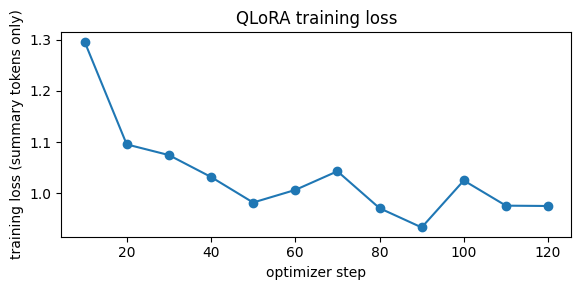

Exercise 5 checks passed.


In [80]:
import matplotlib.pyplot as plt

log = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
steps, losses = zip(*log)
plt.figure(figsize=(6, 3)); plt.plot(steps, losses, marker="o")
plt.xlabel("optimizer step"); plt.ylabel("training loss (summary tokens only)")
plt.title("QLoRA training loss"); plt.tight_layout(); plt.show()
assert all(math.isfinite(l) for l in losses), "a NaN/inf loss usually means an fp16 overflow: lower the learning rate"
assert losses[-1] < losses[0], "the loss should go down over the epoch"
print("Exercise 5 checks passed.")

## Exercise 6 - Evaluate the fine-tuned model (3 marks)


In [81]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} summaries in {time.perf_counter() - start:.0f} s")

generated 60 summaries in 58 s


In [82]:
tuned_rouge = rouge(tuned_preds, eval_refs)
wins = sum(
    scorer.score(ref, tuned)["rougeL"].fmeasure > scorer.score(ref, base)["rougeL"].fmeasure
    for ref, tuned, base in zip(eval_refs, tuned_preds, base_preds)
)

In [83]:
print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.0f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.0f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
assert set(tuned_rouge) == set(ROUGE_KEYS) and 0 <= wins <= N_EVAL
print("Exercise 6 checks passed.")

               rouge1   rouge2   rougeL   words
base             32.1      8.4     23.0      33
QLoRA            45.3     18.5     37.0      22
reference                                    22

QLoRA ROUGE-L higher on 54 of 60 dialogues
Exercise 6 checks passed.


## Exercise 7 - Blind human evaluation (4 marks)

ROUGE cannot tell a fluent but wrong summary from a correct paraphrase. Read six examples yourself. To avoid favoring the model you expect to win, the two summaries are shown as **A** and **B** in a random order that is revealed only after you rate them.

Rate each summary on two criteria:

| Score | **Faithfulness**: is everything it says supported by the dialogue? | **Coverage**: does it capture the main point(s)? |
| --- | --- | --- |
| 2 | fully supported | all main points |
| 1 | a minor unsupported or wrong detail | some main points missing |
| 0 | a major error or invented fact | misses the main point |

In [84]:
HUMAN_IDS = random.Random(SEED).sample(range(N_EVAL), 6)
order = {}                                            # example index -> which model is "A"
for i in HUMAN_IDS:
    order[i] = random.Random(SEED + i).choice(["base", "QLoRA"])
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i][:1200] + (" …" if len(eval_dialogues[i]) > 1200 else ""))
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")

=================== example 40 ===================
#Person1#: When were you born may I ask?
#Person2#: On 20th May 1963.
#Person1#: Do you know what it was according to the lunar calendar?
#Person2#: 27th day of the fourth month.
#Person1#: By the way, could you tell me when the film will begin?
#Person2#: It will begin at five thirty.
#Person1#: I am frigid I can't be there on time.
#Person2#: You can see it tomorrow.
#Person1#: I don't want to miss it today.
#Person2#: See you.
#Person1#: See you.

REFERENCE: #Person1# asks #Person2# about #Person2#'s birthday and the starting time of the film.
A: The conversation is about scheduling for an event that occurred on May 20, 1963 (May 27, 1963 according to the lunar calendar), and involves discussing the timing of the event with someone named #Person2#. #Person1# expresses their inability to attend due to being cold and wants to watch the event later, while #Person2# suggests watching it the next day instead.
B: #Person2#'s birthday is o

In [87]:
# One entry per example, in the order printed above. Replace None with 0, 1, or 2.
my_scores = [
    (2, 2, 1, 2, "B invented a detail"),   # example 1
    (2, 1, 2, 2, "A missed the date"),     # example 2
    (2, 2, 2, 2, "both fine"),             # example 3
    (1, 2, 2, 2, ""),                      # example 4
    (2, 2, 2, 1, ""),                      # example 5
    (2, 2, 1, 1, ""),                      # example 6
]

ratings = {i: {"A_faithful": af, "A_coverage": ac, "B_faithful": bf, "B_coverage": bc, "note": note}
           for i, (af, ac, bf, bc, note) in zip(HUMAN_IDS, my_scores)}

In [88]:
assert all(isinstance(v, int) and 0 <= v <= 2 for r in ratings.values() for k, v in r.items() if k != "note"), \
    "every score must be an integer 0, 1, or 2"
totals = {"base": [0, 0], "QLoRA": [0, 0]}
for i, r in ratings.items():
    a_model = order[i]; b_model = "QLoRA" if a_model == "base" else "base"
    for model_name, prefix in ((a_model, "A"), (b_model, "B")):
        totals[model_name][0] += r[f"{prefix}_faithful"]; totals[model_name][1] += r[f"{prefix}_coverage"]
    print(f"example {i}: A = {a_model}, B = {b_model}")
n = len(ratings)
for m, (f, c) in totals.items():
    print(f"{m:<6} mean faithfulness {f / n:.2f} | mean coverage {c / n:.2f}  (out of 2)")
print("Exercise 7 checks passed.")

example 40: A = base, B = QLoRA
example 7: A = base, B = QLoRA
example 1: A = base, B = QLoRA
example 47: A = base, B = QLoRA
example 17: A = base, B = QLoRA
example 15: A = base, B = QLoRA
base   mean faithfulness 1.83 | mean coverage 1.83  (out of 2)
QLoRA  mean faithfulness 1.67 | mean coverage 1.67  (out of 2)
Exercise 7 checks passed.


## Exercise 8 - Save the adapter (1 mark)

Only the LoRA weights are saved. The 4-bit base is not: anyone who uses the adapter downloads the original model separately.

In [89]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(ADAPTER_DIR)
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<32}{f.stat().st_size / 1e6:8.1f} MB")

README.md                            0.0 MB
adapter_config.json                  0.0 MB
adapter_model.safetensors           73.9 MB
